<a href="https://colab.research.google.com/github/Asmitx026/AI-Lab/blob/main/assignment12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Q. Plant Disease Classification using a Convulational Neual Network (CNN) model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential

In [2]:
import kagglehub
from google.colab import userdata
userdata.get('KAGGLE_API_TOKEN')

path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


[[[167 163 196]
  [166 162 195]
  [165 161 194]
  ...
  [185 182 211]
  [183 180 209]
  [181 178 207]]

 [[170 166 199]
  [169 165 198]
  [168 164 197]
  ...
  [186 183 212]
  [184 181 210]
  [183 180 209]]

 [[170 166 199]
  [169 165 198]
  [168 164 197]
  ...
  [188 185 214]
  [186 183 212]
  [185 182 211]]

 ...

 [[100  90 124]
  [102  92 126]
  [104  94 128]
  ...
  [126 110 137]
  [126 110 137]
  [126 110 137]]

 [[101  91 125]
  [102  92 126]
  [103  93 127]
  ...
  [122 106 133]
  [123 107 134]
  [123 107 134]]

 [[104  94 128]
  [103  93 127]
  [102  92 126]
  ...
  [121 105 132]
  [122 106 133]
  [123 107 134]]]
(256, 256, 3)



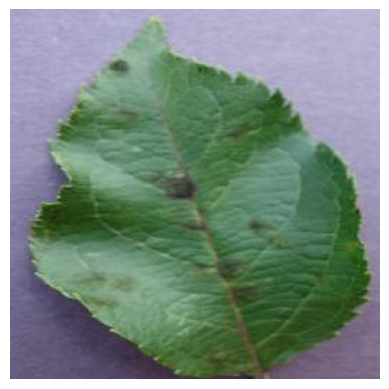

In [3]:
base_dir = f'{path}/plantvillage dataset/color'
image_path = f'{base_dir}/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG'

img = mpimg.imread(image_path)

print(img)
print(img.shape)
print()

plt.imshow(img)
plt.axis('off')
plt.show()

In [4]:
img_size = 224
batch_size = 32

data_gen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='training',
    class_mode='categorical'
)

validation_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='validation',
    class_mode='categorical'
)

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.


In [5]:
model = models.Sequential()

model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_size, img_size, 3)))
model.add(layers.MaxPooling2D(2, 2))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D(2, 2))

model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(train_generator.num_classes, activation='softmax'))


model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    47,776,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,805,158 (182.36 MB)

 Trainable params: 47,805,158 (182.36 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    train_generator,
    steps_per_epoch=200,
    epochs=5,
    validation_data=validation_generator,
    validation_steps=50
)

Epoch 1/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 92s 419ms/step - accuracy: 0.4252 - loss: 2.4003 - val_accuracy: 0.6612 - val_loss: 1.2198
Epoch 2/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 74s 372ms/step - accuracy: 0.6881 - loss: 1.0622 - val_accuracy: 0.6875 - val_loss: 1.1127
Epoch 3/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 68s 343ms/step - accuracy: 0.7727 - loss: 0.7629 - val_accuracy: 0.7825 - val_loss: 0.7205
Epoch 4/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 62s 310ms/step - accuracy: 0.8102 - loss: 0.6151 - val_accuracy: 0.8275 - val_loss: 0.5588
Epoch 5/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 56s 283ms/step - accuracy: 0.8434 - loss: 0.5115 - val_accuracy: 0.8150 - val_loss: 0.5861


In [7]:
val_loss, val_accuracy = model.evaluate(validation_generator, steps=50)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")

50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 217ms/step - accuracy: 0.8319 - loss: 0.5283
Validation Accuracy: 83.19%
Validation Loss: 0.5283


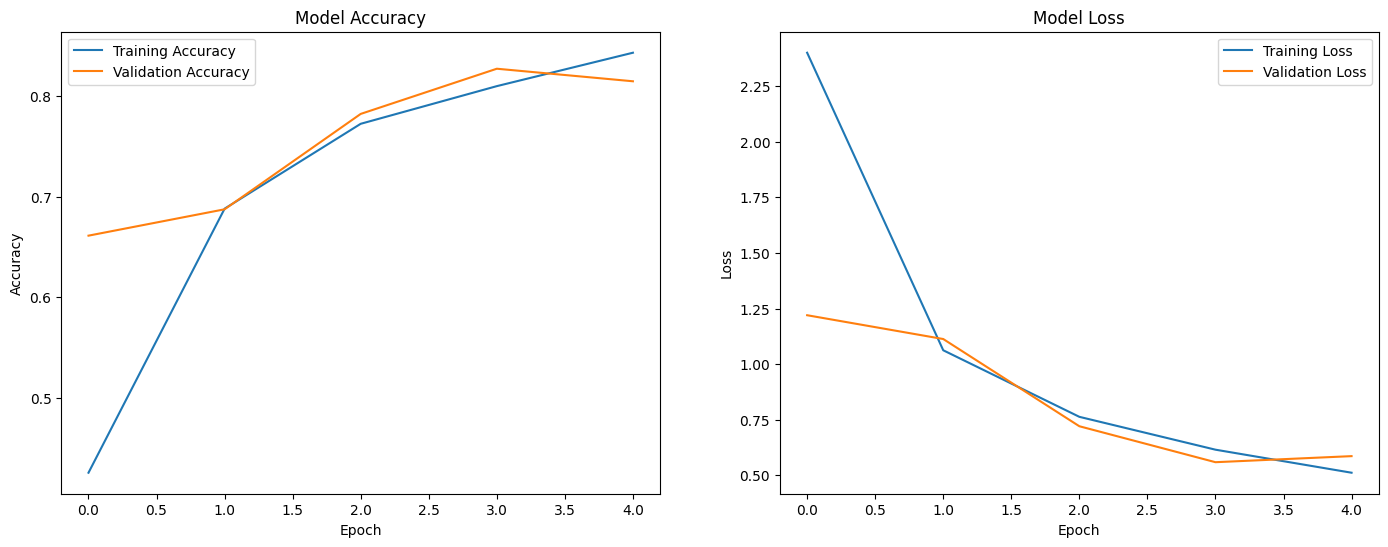

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))

sns.lineplot(ax=ax[0], data=history.history['accuracy'], label='Training Accuracy')
sns.lineplot(ax=ax[0], data=history.history['val_accuracy'], label='Validation Accuracy')
ax[0].set_title('Model Accuracy')
ax[0].set_ylabel('Accuracy')
ax[0].set_xlabel('Epoch')

sns.lineplot(ax=ax[1], data=history.history['loss'], label='Training Loss')
sns.lineplot(ax=ax[1], data=history.history['val_loss'], label='Validation Loss')
ax[1].set_title('Model Loss')
ax[1].set_ylabel('Loss')
ax[1].set_xlabel('Epoch')

plt.show()